# Pitfall 1 — Look-ahead bias

> *A backtest is a simulation of decisions. If the simulation lets you decide
> with information that didn't exist yet, it's not a backtest — it's a replay.*

This notebook follows the project's three-act structure:

1. **The cheat** — a simple signal on real SPY data that produces an absurdly good equity curve.
2. **The reveal** — why that result is impossible, and the exact line of code where honesty is decided.
3. **The fix** — the *same* signal, re-run honestly. The edge disappears.

Nothing in the engine (`src/backtest.py`) is modified. The only thing that changes between
the cheating and the honest run is one argument: `lag`.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, str(Path.cwd().parent / "src"))
from data import load_prices
from backtest import run_backtest

pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
plt.rcParams["figure.dpi"] = 110

## Data

Daily adjusted closes for **SPY** (S&P 500 ETF), 2015-01-01 → 2024-12-31, fetched with `yfinance`
and cached to `data/` as parquet. Ten years, ~2,500 trading days, covering the 2018 sell-off,
the 2020 COVID crash and the 2022 bear market — i.e. not a cherry-picked calm window.

In [2]:
START, END = "2015-01-01", "2024-12-31"
COST_BPS = 1.0   # one-way cost, charged on |Δposition| — same for every run below

px = load_prices("SPY", start=START, end=END)["Close"]
print(f"{len(px)} trading days: {px.index[0].date()} → {px.index[-1].date()}")
px.tail()

2515 trading days: 2015-01-02 → 2024-12-30


Date
2024-12-23   583.2321
2024-12-24   589.7148
2024-12-26   589.7540
2024-12-27   583.5459
2024-12-30   576.8867
Name: Close, dtype: float64

## The strategy: one-day momentum

The rule is about as simple as it gets:

> At the close of each day, look at today's return.
> **If SPY went up today, be long. If it went down, be short.**

$$\text{position}_t = \operatorname{sign}\left(\frac{P_t}{P_{t-1}} - 1\right)$$

Note that this signal is *legitimately computable* at the close of day $t$ — it uses only
prices up to and including $P_t$. There is nothing wrong with the signal itself.
Keep that in mind.

In [3]:
ret = px.pct_change().fillna(0.0)
signal = np.sign(ret)          # +1 after an up day, -1 after a down day, 0 if flat
signal.value_counts().rename("days")

Close
1.0000     1373
-1.0000    1135
0.0000        7
Name: days, dtype: int64

---
# Act 1 — The cheat

Run it through the engine with `lag=0`. No explanation yet — just look at the result.

In [4]:
cheat = run_backtest(px, signal, cost_bps=COST_BPS, lag=0)
cheat.summary().to_frame("lag=0")

,lag=0
CAGR,5.0428
Sharpe,13.6396
MaxDrawdown,-0.0002
Turnover,1.0199
FinalEquity,"62,640,730.4262"


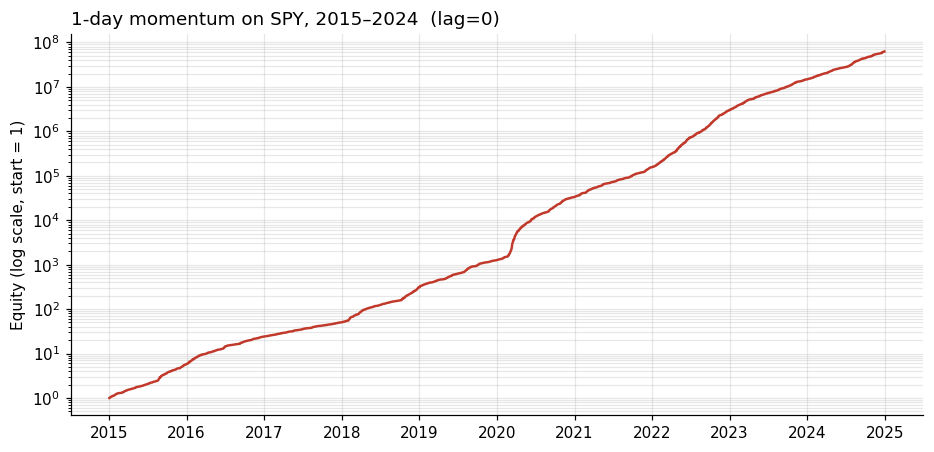

In [5]:
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(cheat.equity, color="#c0392b", lw=1.6)
ax.set_yscale("log")
ax.set_title("1-day momentum on SPY, 2015–2024  (lag=0)", loc="left", fontsize=12)
ax.set_ylabel("Equity (log scale, start = 1)")
ax.grid(alpha=0.3, which="both")
ax.spines[["top", "right"]].set_visible(False)
plt.show()

A Sharpe ratio above **13**. A compound annual growth rate of several **hundred percent**.
$1 turning into tens of millions in ten years. And a maximum drawdown of **essentially zero** (−0.02%, from transaction costs alone) —
through COVID, through 2022 — not a single day where the bet itself lost money.

For reference, the best hedge funds in the world are happy with a Sharpe of 2.
Anything in double digits is not a discovery; it's a bug. The question is *where*.

---
# Act 2 — The reveal

### What the engine promises

`src/backtest.py` is built on one contract:

> `position[t]` is the weight you **decide at the close of day t**.
> It earns the return of **day t+1**.

That contract is enforced by a single line:

```python
effective_pos = position.shift(lag).fillna(0.0)
gross = effective_pos * asset_ret
```

- With `lag=1`, the position decided at the close of day $t$ is shifted onto day $t+1$,
  so it is multiplied by $r_{t+1}$ — a return that **hasn't happened yet** when you decide. Honest.
- With `lag=0`, there is no shift. The position decided at the close of day $t$ is multiplied by
  $r_t$ — the return of **the very day you used to make the decision**.

### Why `lag=0` is cheating

$r_t = P_t / P_{t-1} - 1$ is only known once day $t$ has *closed*. By then, day $t$'s return is
over — you can no longer hold a position during it. `lag=0` lets you
**place today's trade using information you only get after today's market has closed**.

With our signal, this becomes painfully explicit:

$$\text{strategy return}_t = \operatorname{sign}(r_t)\cdot r_t = |r_t|$$

The strategy "earns" the absolute value of every single day's move. Up day? You were long.
Down day? You were short. It cannot lose (apart from the tiny transaction cost), which is exactly
why the drawdown is zero.

We can verify this directly:

In [6]:
gross_cheat = signal.shift(0) * ret        # what the engine computes with lag=0 (before costs)
print("strategy gross return == |daily return| on every day:",
      np.allclose(gross_cheat, ret.abs()))

strategy gross return == |daily return| on every day: True


### The same days, side by side

Here is what the two settings actually multiply together on a handful of days.
Read each row as "what return does the decision get paid on?"

In [7]:
window = slice("2020-03-09", "2020-03-18")   # the heart of the COVID crash
side_by_side = pd.DataFrame({
    "SPY return r[t]":           ret,
    "signal decided at close t": signal,
    "lag=0: position held on t": signal.shift(0),
    "lag=0: P&L on t":           signal.shift(0) * ret,
    "lag=1: position held on t": signal.shift(1),
    "lag=1: P&L on t":           signal.shift(1) * ret,
}).loc[window]
side_by_side

,SPY return r[t],signal decided at close t,lag=0: position held on t,lag=0: P&L on t,lag=1: position held on t,lag=1: P&L on t
Date,,,,,,
2020-03-09,-0.0781,-1.0000,-1.0000,0.0781,-1.0000,0.0781
2020-03-10,0.0517,1.0000,1.0000,0.0517,-1.0000,-0.0517
2020-03-11,-0.0487,-1.0000,-1.0000,0.0487,1.0000,-0.0487
2020-03-12,-0.0957,-1.0000,-1.0000,0.0957,-1.0000,0.0957
2020-03-13,0.0855,1.0000,1.0000,0.0855,-1.0000,-0.0855
2020-03-16,-0.1094,-1.0000,-1.0000,0.1094,1.0000,-0.1094
2020-03-17,0.0540,1.0000,1.0000,0.0540,-1.0000,-0.0540
2020-03-18,-0.0506,-1.0000,-1.0000,0.0506,1.0000,-0.0506


In the `lag=0` columns the position always has the same sign as that day's return, so every
P&L is positive — including on the −11% day of 16 March 2020. In the `lag=1` columns, the
position is *yesterday's* decision, and it is right some days and wrong others, the way real
trading is.

### Why this bug is so common in practice

Nobody writes `lag=0` on purpose. The same mistake appears in disguise as:

- computing a signal and a return from the **same row** of a DataFrame and multiplying them;
- forgetting a `.shift(1)` after a rolling indicator (moving average, z-score, RSI…);
- normalising features with the **full-sample** mean/std, which bakes future data into every past point;
- using data stamped with the period it *describes* rather than the date it was *published*
  (earnings, macro releases, index membership).

The tell-tale signs are the ones we just saw: a Sharpe far above anything achievable,
and an equity curve that is suspiciously smooth.

---
# Act 3 — The fix

Same prices, same signal, same costs. Only `lag` changes: decide at the close of $t$,
get paid on $t+1$.

In [8]:
honest = run_backtest(px, signal, cost_bps=COST_BPS, lag=1)
honest.summary().to_frame("lag=1")

,lag=1
CAGR,-0.0765
Sharpe,-0.3628
MaxDrawdown,-0.6517
Turnover,1.0199
FinalEquity,0.4521


The Sharpe collapses from double digits to roughly **zero — in fact slightly negative**.
Once the strategy has to predict tomorrow from today, it has no edge at all: SPY's daily
returns carry essentially no one-day momentum (if anything, a mild reversal),
and the daily flipping between long and short just bleeds transaction costs. Over the decade it
loses about half its value, with a 65% maximum drawdown.

That is the honest answer, and it's the boring one. The entire "edge" in Act 1 came from
information the strategy should never have had.

---
# Before / after

Both curves on one chart, with buy-and-hold SPY as a neutral reference.
A log scale is required — on a linear scale the cheating curve makes the other two invisible.

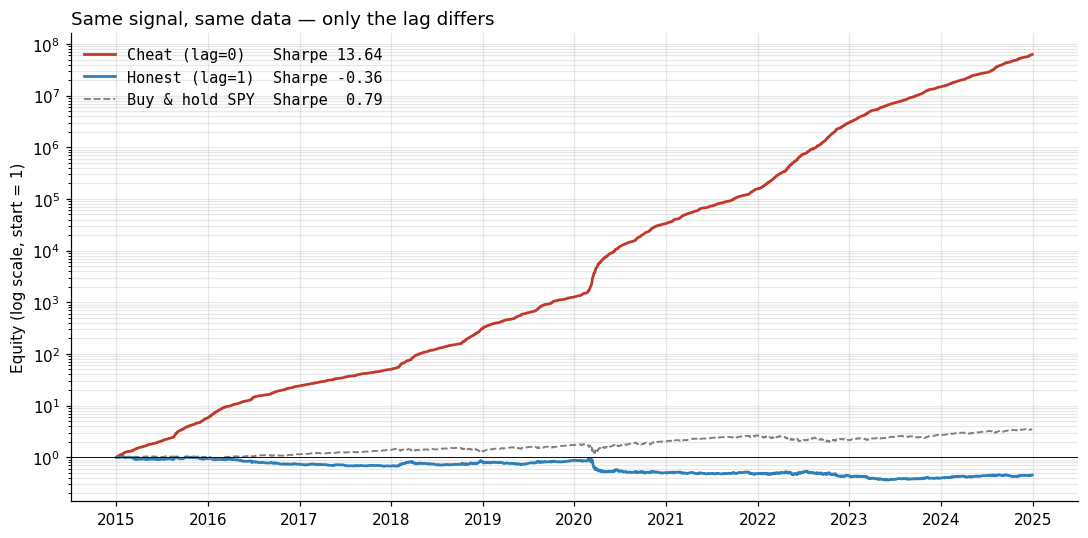

In [9]:
buy_hold = run_backtest(px, pd.Series(1.0, index=px.index), cost_bps=COST_BPS, lag=1)

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(cheat.equity,    color="#c0392b", lw=1.8, label=f"Cheat (lag=0)   Sharpe {cheat.sharpe:5.2f}")
ax.plot(honest.equity,   color="#2c7fb8", lw=1.8, label=f"Honest (lag=1)  Sharpe {honest.sharpe:5.2f}")
ax.plot(buy_hold.equity, color="#7f7f7f", lw=1.2, ls="--", label=f"Buy & hold SPY  Sharpe {buy_hold.sharpe:5.2f}")
ax.set_yscale("log")
ax.axhline(1.0, color="black", lw=0.6)
ax.set_title("Same signal, same data — only the lag differs", loc="left", fontsize=12)
ax.set_ylabel("Equity (log scale, start = 1)")
ax.legend(loc="upper left", frameon=False, prop={"family": "monospace"})
ax.grid(alpha=0.3, which="both")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

In [10]:
comparison = pd.DataFrame({
    "Cheat (lag=0)":  cheat.summary(),
    "Honest (lag=1)": honest.summary(),
    "Buy & hold":     buy_hold.summary(),
}).loc[["Sharpe", "CAGR", "MaxDrawdown"]].T

comparison.style.format({"Sharpe": "{:.2f}", "CAGR": "{:.1%}", "MaxDrawdown": "{:.1%}"})

,Sharpe,CAGR,MaxDrawdown
Cheat (lag=0),13.64,504.3%,-0.0%
Honest (lag=1),-0.36,-7.6%,-65.2%
Buy & hold,0.79,13.1%,-33.7%


---
# Takeaways

- **The signal wasn't the bug — the timing was.** A perfectly valid signal becomes a
  time machine the moment it is paid on the same bar it was computed from.
- **One line decides honesty.** In this engine it is `position.shift(lag)`. In any backtest,
  the question to ask is: *"at the moment this position is taken, could I have known every input?"*
- **Implausible results are evidence of a bug, not of skill.** A Sharpe of 13 and a zero
  drawdown over a decade that includes COVID should trigger an audit, not a celebration.
- **Fixing it costs everything.** Sharpe went from ~13.6 to below zero. That gap is the size
  of the illusion — and the reason look-ahead bias is the first thing to rule out.

*A note on what `lag=1` still assumes:* it treats the trade as filled at the same close that
generated the signal. That's the standard convention for daily close-to-close backtests, but
strictly you can't observe the close and trade on it at the same instant. A stricter version would
trade at the next open, or use `lag=2` (Sharpe ≈ −0.18 here); either way the conclusion — no edge — is unchanged.